# Etapa 6 — Lógica Fuzzy: sistema Mamdani para o risco de hospitalização

**Pergunta prática (a mesma das etapas anteriores):** dado o perfil e os sintomas de um paciente com dengue notificado, ele será hospitalizado?

**Entrada:** as probabilidades de hospitalização calculadas pela rede Bayesiana da Etapa 5 para os pacientes do teste (`etapa5_probabilidades_teste.csv`), que já trazem os atributos e o desfecho real de cada paciente. São os mesmos pacientes de teste das Etapas 1, 2, 4 e 5.

O sistema fuzzy é implementado **do zero** (NumPy) e conferido com o **scikit-fuzzy**, como pede o enunciado.

Antes de rodar, envie para `/content` o arquivo `etapa5_probabilidades_teste.csv` (gerado pela Etapa 5). Depois, rode as células em ordem (Ambiente de execução → Executar tudo).

In [1]:
# No Colab, o scikit-fuzzy não vem instalado
!pip install -q scikit-fuzzy

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import skfuzzy as fuzz
from skfuzzy import control as ctrl

SEED = 42
np.random.seed(SEED)
CAMINHO_ETAPA5 = "/content/etapa5_probabilidades_teste.csv"
assert os.path.exists(CAMINHO_ETAPA5), "envie o arquivo etapa5_probabilidades_teste.csv (saída da Etapa 5) para /content"
print("ok")

ok


## 1. Funções do sistema fuzzy (tudo do zero)

* **Funções de pertinência:** triangular e trapezoidal. A trapezoidal aceita "ombros" (a = b ou c = d), usados nos conjuntos das pontas, que valem 1 até a borda do universo.
* **Operadores:** E = mínimo (t-norma), OU = máximo (s-norma).
* **Inferência de Mamdani:** cada regra corta o conjunto de saída na sua força de ativação (implicação pelo mínimo); os conjuntos cortados são unidos pelo máximo (agregação).
* **Defuzzificação:** centróide (centro de massa) do conjunto agregado.

In [3]:
def triangular(x, a, b, c):
    """Pertinência triangular: 0 em a, 1 em b, 0 em c."""
    x = np.asarray(x, dtype=float)
    sobe = (x - a) / (b - a) if b > a else np.ones_like(x)
    desce = (c - x) / (c - b) if c > b else np.ones_like(x)
    return np.clip(np.minimum(sobe, desce), 0.0, 1.0)


def trapezoidal(x, a, b, c, d):
    """Pertinência trapezoidal: sobe de a a b, vale 1 de b a c, desce de c a d.
    Com a = b (ou c = d), o conjunto é um 'ombro' e vale 1 até a borda."""
    x = np.asarray(x, dtype=float)
    sobe = np.ones_like(x) if a == b else np.clip((x - a) / (b - a), 0.0, 1.0)
    desce = np.ones_like(x) if c == d else np.clip((d - x) / (d - c), 0.0, 1.0)
    return np.where((x < a) | (x > d), 0.0, np.minimum(sobe, desce))


def E(*graus):
    return min(graus)        # t-norma do mínimo


def OU(*graus):
    return max(graus)        # s-norma do máximo


def centroide(universo, mu):
    """Centro de massa do conjunto agregado (integral pela regra dos trapézios)."""
    def area(f):
        return np.sum((universo[1:] - universo[:-1]) * (f[1:] + f[:-1]) / 2)
    return float(area(universo * mu) / area(mu))

## 2. Variáveis linguísticas e funções de pertinência

| Variável | Papel | Universo | Conjuntos |
|---|---|---|---|
| `p_rede` | entrada | [0, 1] | baixa, média, alta |
| `sinais` | entrada | [0, 2] | nenhum, um, dois |
| `risco` | saída | [0, 100] | baixo, moderado, alto |

* **`p_rede`** é a probabilidade de hospitalização dada pela rede Bayesiana (Etapa 5), na base balanceada, a mesma escala do limiar 0,5 usado em todas as etapas.
* **`sinais`** conta quantos dos dois achados mais associados à internação estão presentes: **leucopenia** e **vômito** (vômito persistente é sinal de alarme da dengue). Vale 0, 1 ou 2.
* **`risco`** é a saída, de 0 a 100. A decisão final é "hospitalizar" quando o risco é pelo menos 50, o equivalente ao limiar 0,5.

Os conjuntos de `risco` são os da primeira versão desta etapa. Os de `p_rede` foram ajustados para se sobreporem: em qualquer ponto, as pertinências de baixa, média e alta somam 1. Na primeira versão, entre 0,4 e 0,6 só o conjunto "média" era ativado, e o risco ficava parado em exatamente 50, bem em cima do limiar de decisão; com a sobreposição, o risco varia continuamente e, sem sinais de alarme, cruza 50 exatamente em `p_rede` = 0,5, como o limiar rígido.

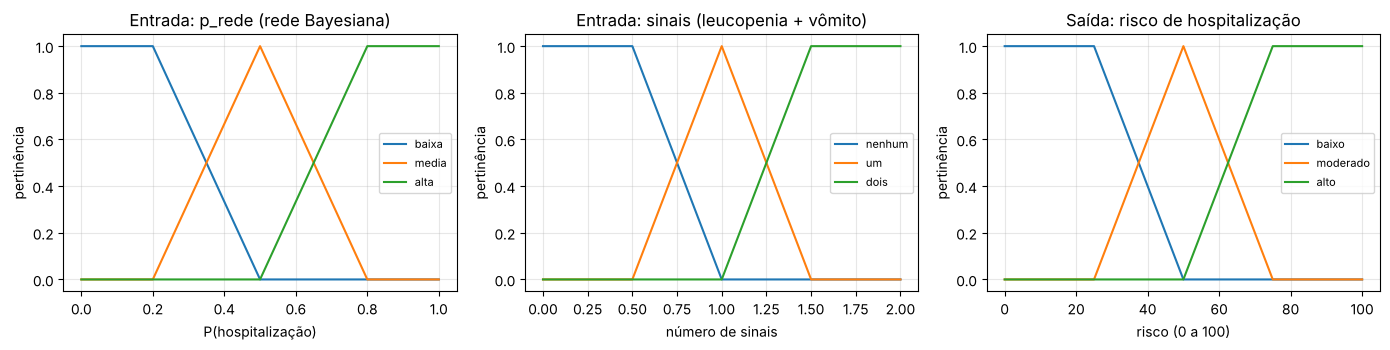

In [4]:
U_P = np.linspace(0, 1, 101)
U_S = np.linspace(0, 2, 201)
U_R = np.linspace(0, 100, 1001)

def fuzz_p(p):
    return {"baixa": trapezoidal(p, 0.0, 0.0, 0.2, 0.5),
            "media": triangular(p, 0.2, 0.5, 0.8),
            "alta":  trapezoidal(p, 0.5, 0.8, 1.0, 1.0)}

def fuzz_s(s):
    return {"nenhum": trapezoidal(s, 0.0, 0.0, 0.5, 1.0),
            "um":     triangular(s, 0.5, 1.0, 1.5),
            "dois":   trapezoidal(s, 1.0, 1.5, 2.0, 2.0)}

SAIDA = {"baixo":    trapezoidal(U_R, 0, 0, 25, 50),
         "moderado": triangular(U_R, 25, 50, 75),
         "alto":     trapezoidal(U_R, 50, 75, 100, 100)}

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for nome, mu in fuzz_p(U_P).items():
    ax[0].plot(U_P, mu, label=nome)
ax[0].set_title("Entrada: p_rede (rede Bayesiana)"); ax[0].set_xlabel("P(hospitalização)")
for nome, mu in fuzz_s(U_S).items():
    ax[1].plot(U_S, mu, label=nome)
ax[1].set_title("Entrada: sinais (leucopenia + vômito)"); ax[1].set_xlabel("número de sinais")
for nome, mu in SAIDA.items():
    ax[2].plot(U_R, mu, label=nome)
ax[2].set_title("Saída: risco de hospitalização"); ax[2].set_xlabel("risco (0 a 100)")
for a in ax:
    a.set_ylabel("pertinência"); a.legend(fontsize=8); a.grid(alpha=.3)
fig.tight_layout(); fig.savefig("etapa6_pertinencia.png", dpi=150); plt.show()

## 3. Base de regras

Quatro regras Se-Então, escritas como um médico as diria, com os operadores E e OU. A ideia é que o risco **acompanhe a estimativa da rede** e que os **sinais de alarme reforcem** o risco quando a rede está em dúvida, ou quando os dois sinais aparecem juntos:

1. **Se** a probabilidade da rede é **alta** **OU** o paciente tem **dois** sinais de alarme, **então** o risco é **alto**.
2. **Se** a probabilidade da rede é **média**, **então** o risco é **moderado**.
3. **Se** a probabilidade da rede é **baixa**, **então** o risco é **baixo**.
4. **Se** a probabilidade da rede é **média** **E** o paciente tem **um** sinal de alarme, **então** o risco é **alto**.

Observação: leucopenia e vômito já são nós da rede da Etapa 5, então a parte "dois sinais" da regra 1 e a regra 4 dão a eles um **peso extra**, como faz um protocolo clínico que manda reavaliar qualquer paciente com sinal de alarme, independentemente do resto.

In [5]:
REGRAS = [
    ("Se p_rede é alta OU sinais é dois, então risco é alto",      lambda P, S: OU(P["alta"], S["dois"]),  "alto"),
    ("Se p_rede é média, então risco é moderado",                  lambda P, S: P["media"],                "moderado"),
    ("Se p_rede é baixa, então risco é baixo",                     lambda P, S: P["baixa"],                "baixo"),
    ("Se p_rede é média E sinais é um, então risco é alto",        lambda P, S: E(P["media"], S["um"]),    "alto"),
]


def inferir(p, s, detalhe=False):
    """Mamdani: ativação de cada regra, corte pelo mínimo, agregação pelo máximo, centróide."""
    P = {k: float(v) for k, v in fuzz_p(p).items()}
    S = {k: float(v) for k, v in fuzz_s(s).items()}
    agregado = np.zeros_like(U_R)
    ativacoes = []
    for texto, antecedente, consequente in REGRAS:
        forca = antecedente(P, S)
        ativacoes.append((texto, forca))
        agregado = np.maximum(agregado, np.minimum(forca, SAIDA[consequente]))
    r = centroide(U_R, agregado)
    return (r, P, S, ativacoes, agregado) if detalhe else r


for i, (texto, _, _) in enumerate(REGRAS, 1):
    print(f"R{i}: {texto}")

R1: Se p_rede é alta OU sinais é dois, então risco é alto
R2: Se p_rede é média, então risco é moderado
R3: Se p_rede é baixa, então risco é baixo
R4: Se p_rede é média E sinais é um, então risco é alto


## 4. Dados: probabilidades da Etapa 5 e sinais de alarme

In [6]:
d = pd.read_csv(CAMINHO_ETAPA5)
d["sinais"] = (d["LEUCOPENIA"] == 1).astype(int) + (d["VOMITO"] == 1).astype(int)
y = d["alvo"].to_numpy()
p = d["p_rede"].to_numpy()
s = d["sinais"].to_numpy()

print("pacientes de teste:", len(d), "| hospitalizados:", int(y.sum()))
print("\nnúmero de sinais de alarme e taxa real de hospitalização:")
print(d.groupby("sinais")["alvo"].agg(pacientes="size", taxa_hosp="mean").round(3).to_string())

pacientes de teste: 11876 | hospitalizados: 5938

número de sinais de alarme e taxa real de hospitalização:
        pacientes  taxa_hosp
sinais                      
0            7013      0.411
1            4337      0.597
2             526      0.888


## 5. Exemplo passo a passo

Um paciente na fronteira da decisão: a rede dá cerca de 0,49 (abaixo do limiar, a decisão "hard" seria **não hospitalizar**) e ele tem um sinal de alarme.

{'regiao': 'sul', 'faixa_etaria': 'adulto', 'LEUCOPENIA': 2.0, 'VOMITO': 1.0, 'HIPERTENSA': 2.0, 'alvo': 1}

p_rede = 0.4970 | sinais = 1
fuzzificação de p_rede: {'baixa': 0.01, 'media': 0.99, 'alta': 0.0}
fuzzificação de sinais: {'nenhum': 0.0, 'um': 1.0, 'dois': 0.0}

ativação das regras:
  0.000  Se p_rede é alta OU sinais é dois, então risco é alto
  0.990  Se p_rede é média, então risco é moderado
  0.010  Se p_rede é baixa, então risco é baixo
  0.990  Se p_rede é média E sinais é um, então risco é alto

risco (centróide) = 68.6 -> hospitalizar
decisão hard (p_rede >= 0,5): não hospitalizar


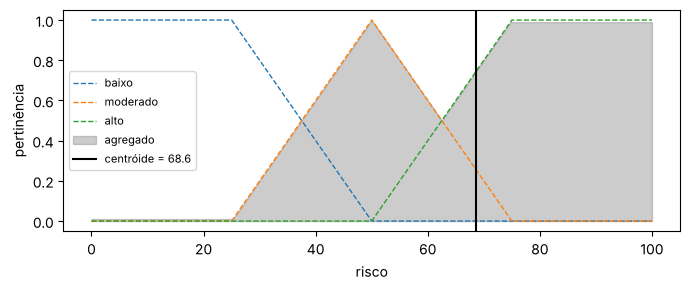

In [7]:
i = int(np.argmin(np.abs(p - 0.49) + 10 * (s != 1)))
r, P, S, ativ, ag = inferir(p[i], s[i], detalhe=True)
print(d.loc[i, ["regiao", "faixa_etaria", "LEUCOPENIA", "VOMITO", "HIPERTENSA", "alvo"]].to_dict())
print(f"\np_rede = {p[i]:.4f} | sinais = {s[i]}")
print("fuzzificação de p_rede:", {k: round(v, 3) for k, v in P.items()})
print("fuzzificação de sinais:", {k: round(v, 3) for k, v in S.items()})
print("\nativação das regras:")
for texto, f in ativ:
    print(f"  {f:.3f}  {texto}")
print(f"\nrisco (centróide) = {r:.1f} -> {'hospitalizar' if r >= 50 else 'não hospitalizar'}")
print(f"decisão hard (p_rede >= 0,5): {'hospitalizar' if p[i] >= 0.5 else 'não hospitalizar'}")

plt.figure(figsize=(7, 3))
for nome, mu in SAIDA.items():
    plt.plot(U_R, mu, "--", lw=1, label=nome)
plt.fill_between(U_R, ag, alpha=.4, color="gray", label="agregado")
plt.axvline(r, color="k", label=f"centróide = {r:.1f}")
plt.xlabel("risco"); plt.ylabel("pertinência"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Sistema aplicado a todos os pacientes e conferência com o scikit-fuzzy

O mesmo sistema (mesmos conjuntos, mesmas regras, mínimo para o E e para a implicação, máximo para o OU e para a agregação, centróide) é montado no scikit-fuzzy. Os riscos devem coincidir até o erro de arredondamento.

In [8]:
# do zero
risco = np.array([inferir(a, b) for a, b in zip(p, s)])

# scikit-fuzzy
pr = ctrl.Antecedent(U_P, "p_rede")
si = ctrl.Antecedent(U_S, "sinais")
rk = ctrl.Consequent(U_R, "risco", defuzzify_method="centroid")
pr["baixa"] = fuzz.trapmf(U_P, [0.0, 0.0, 0.2, 0.5])
pr["media"] = fuzz.trimf(U_P, [0.2, 0.5, 0.8])
pr["alta"] = fuzz.trapmf(U_P, [0.5, 0.8, 1.0, 1.0])
si["nenhum"] = fuzz.trapmf(U_S, [0.0, 0.0, 0.5, 1.0])
si["um"] = fuzz.trimf(U_S, [0.5, 1.0, 1.5])
si["dois"] = fuzz.trapmf(U_S, [1.0, 1.5, 2.0, 2.0])
rk["baixo"] = fuzz.trapmf(U_R, [0, 0, 25, 50])
rk["moderado"] = fuzz.trimf(U_R, [25, 50, 75])
rk["alto"] = fuzz.trapmf(U_R, [50, 75, 100, 100])
sistema = ctrl.ControlSystem([
    ctrl.Rule(pr["alta"] | si["dois"], rk["alto"]),
    ctrl.Rule(pr["media"], rk["moderado"]),
    ctrl.Rule(pr["baixa"], rk["baixo"]),
    ctrl.Rule(pr["media"] & si["um"], rk["alto"]),
])
sim = ctrl.ControlSystemSimulation(sistema)

# os pacientes repetem muito as mesmas combinações: calcula cada uma uma vez
combos = d[["p_rede", "sinais"]].drop_duplicates()
sk = {}
for a, b in combos.itertuples(index=False):
    sim.input["p_rede"] = a
    sim.input["sinais"] = b
    sim.compute()
    sk[(a, b)] = sim.output["risco"]
risco_sk = np.array([sk[(a, b)] for a, b in zip(p, s)])

print("combinações diferentes de (p_rede, sinais):", len(combos))
print(f"maior diferença do zero x scikit-fuzzy: {np.max(np.abs(risco - risco_sk)):.2e}")

combinações diferentes de (p_rede, sinais): 107
maior diferença do zero x scikit-fuzzy: 1.13e-04


## 7. Fuzzy x decisão "hard" (limiar 0,5)

A decisão hard hospitaliza quando `p_rede >= 0,5`. A decisão fuzzy hospitaliza quando `risco >= 50`. A AUC usa o valor contínuo de cada uma (`p_rede` ou `risco`).

In [9]:
def avaliar(y, decisao, escore):
    vp = int(np.sum((decisao == 1) & (y == 1))); fp = int(np.sum((decisao == 1) & (y == 0)))
    fn = int(np.sum((decisao == 0) & (y == 1))); vn = int(np.sum((decisao == 0) & (y == 0)))
    return {"acuracia": (vp + vn) / len(y), "precisao": vp / (vp + fp), "recall": vp / (vp + fn),
            "AUC": roc_auc_score(y, escore), "VP": vp, "FP": fp, "FN": fn, "VN": vn}

hard = (p >= 0.5).astype(int)
fuzzy = (risco >= 50).astype(int)
tab = pd.DataFrame([avaliar(y, hard, p), avaliar(y, fuzzy, risco)],
                   index=["hard (p_rede >= 0,5)", "fuzzy (risco >= 50)"])
print(tab.round(4).to_string())

mud = hard != fuzzy
print(f"\ndecisões diferentes: {mud.sum()} de {len(y)} pacientes ({mud.mean():.1%})")
print("hard = não -> fuzzy = sim:", int(np.sum(mud & (fuzzy == 1))), "| hard = sim -> fuzzy = não:", int(np.sum(mud & (fuzzy == 0))))
print(f"taxa real de hospitalização entre eles: {y[mud].mean():.3f}")

                      acuracia  precisao  recall     AUC    VP    FP    FN    VN
hard (p_rede >= 0,5)    0.6567    0.6628  0.6379  0.7147  3788  1927  2150  4011
fuzzy (risco >= 50)     0.6275    0.6033  0.7447  0.7060  4422  2908  1516  3030

decisões diferentes: 1615 de 11876 pacientes (13.6%)
hard = não -> fuzzy = sim: 1615 | hard = sim -> fuzzy = não: 0
taxa real de hospitalização entre eles: 0.393


**Na fronteira.** O limiar rígido trata da mesma forma um paciente com 0,49 e um com 0,30, e de formas opostas pacientes com 0,49 e 0,51. Abaixo, os pacientes com `p_rede` entre 0,40 e 0,60, separados pelo número de sinais de alarme.

pacientes na faixa 0,40 a 0,60: 3573
        pacientes  taxa_real_hosp  risco_medio  hosp_hard  hosp_fuzzy
sinais                                                               
0            2340           0.485       52.371      0.634       0.634
1            1233           0.460       63.571      0.255       1.000


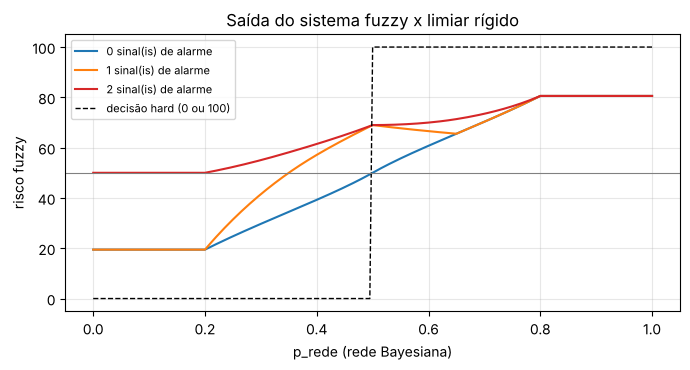

In [10]:
f = (p >= 0.40) & (p < 0.60)
fr = d[f].assign(risco=risco[f], hard=hard[f], fuzzy=fuzzy[f])
print(f"pacientes na faixa 0,40 a 0,60: {f.sum()}")
print(fr.groupby("sinais").agg(pacientes=("alvo", "size"), taxa_real_hosp=("alvo", "mean"),
                               risco_medio=("risco", "mean"), hosp_hard=("hard", "mean"),
                               hosp_fuzzy=("fuzzy", "mean")).round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.8))
grade = np.linspace(0, 1, 201)
for k, cor in [(0, "tab:blue"), (1, "tab:orange"), (2, "tab:red")]:
    ax.plot(grade, [inferir(g, k) for g in grade], color=cor, label=f"{k} sinal(is) de alarme")
ax.plot(grade, 100 * (grade >= 0.5), "k--", lw=1, label="decisão hard (0 ou 100)")
ax.axhline(50, color="gray", lw=.8)
ax.set_xlabel("p_rede (rede Bayesiana)"); ax.set_ylabel("risco fuzzy")
ax.set_title("Saída do sistema fuzzy x limiar rígido"); ax.legend(fontsize=8); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig("etapa6_risco.png", dpi=150); plt.show()

## 8. Interpretabilidade e discussão

* **Cada regra é legível por um especialista.** São frases do tipo "se a rede indica probabilidade média e o paciente tem um sinal de alarme, o risco é alto", que um médico pode ler, contestar e ajustar sem saber programar. A decisão de cada paciente pode ser explicada mostrando quais regras dispararam e com que força (seção 5).
* **A saída é suave.** Em vez de um "sim/não" que muda bruscamente em 0,5, o risco varia de forma contínua e mostra o quanto o paciente está perto da fronteira. Sem sinais de alarme, o sistema concorda com o limiar rígido em todos os pacientes; as diferenças vêm só dos sinais de alarme (a parte "dois sinais" da regra 1 e a regra 4).
* **Troca entre recall e precisão.** As regras com sinais de alarme mudaram a decisão de 13,6% dos pacientes, todos de "não hospitalizar" para "hospitalizar". O recall subiu (menos hospitalizações não previstas), mas a precisão e a acurácia caíram, porque só 39% desses pacientes foram de fato hospitalizados. Em triagem, deixar de identificar um caso que será internado costuma ser mais grave do que reavaliar um caso leve, então essa troca pode ser aceitável, mas ela é uma **política explícita nas regras**, que o especialista pode rever, e não um ganho de informação.
* **Por que o fuzzy não superou o limiar aqui?** Na faixa de 0,40 a 0,60, os pacientes com um sinal de alarme tiveram taxa real de hospitalização **menor** (46%) que os sem sinal (48,5%). Ou seja, depois que a rede já levou leucopenia e vômito em conta, contá-los de novo não acrescenta informação. O fuzzy tende a superar o limiar rígido quando a segunda entrada traz algo que o modelo **não** viu (por exemplo, a avaliação clínica do médico, ou dados que não estão no Sinan) e quando os dados são ruidosos ou as fronteiras entre as classes são ambíguas. Nesses casos, as regras permitem combinar a probabilidade do modelo com esse conhecimento extra de forma gradual e explicável.

In [11]:
saida = d[["regiao", "faixa_etaria", "LEUCOPENIA", "VOMITO", "HIPERTENSA", "alvo", "p_rede", "sinais"]].copy()
saida["risco_fuzzy"] = risco.round(2)
saida["decisao_hard"] = hard
saida["decisao_fuzzy"] = fuzzy
saida.to_csv("etapa6_decisoes_teste.csv", index=False)
print("salvo: etapa6_decisoes_teste.csv", saida.shape)
print(saida.head().to_string(index=False))

salvo: etapa6_decisoes_teste.csv (11876, 11)
      regiao faixa_etaria  LEUCOPENIA  VOMITO  HIPERTENSA  alvo   p_rede  sinais  risco_fuzzy  decisao_hard  decisao_fuzzy
centro-oeste       adulto         2.0     1.0         2.0     0 0.419504       1        59.62             0              1
centro-oeste       adulto         2.0     2.0         2.0     0 0.281597       0        27.91             0              0
centro-oeste       adulto         2.0     2.0         2.0     1 0.281597       0        27.91             0              0
     sudeste       adulto         2.0     2.0         2.0     1 0.243151       0        24.05             0              0
    nordeste      crianca         1.0     2.0         2.0     1 0.899372       1        80.56             1              1
